# Bond Valuation, Funding and Rate Risk

**Kappa Foundation, BFIN WS2026 | Workstream 2: liability funding with the case bonds**

This notebook reproduces, in Python and without network access, the bond analysis of `bond_funding/Kappa_Bond_Funding_Model.xlsx`
and cross-checks every key figure against that workbook. It answers four questions:

1. Which contractual bond cash flows meet the 31 December 2024 (USD 2.4m) and 31 December 2027 (USD 3.6m) obligations, and at what initial cost?
2. How exposed is the funding sleeve to interest-rate changes, and does that exposure affect the ability to pay?
3. How does the recommended maturity-matched candidate compare with a credible alternative?
4. What growth return does the residual capital need in order to preserve USD 8.0m of December 2022 purchasing power by 31 December 2030?

| Convention | Treatment |
|---|---|
| Case bonds | USD 1,000 face, annual coupons on 31 December from 2023, non-callable; no default risk and no taxes (case terms) |
| Quotes | Fictional executable quotes from the case exhibits; no historical or future bond price series exists, so rate effects are scenario analysis, not forecasts |
| Term structure | The case gives no 4-year instrument; 4-year spot = 3-year spot is an **explicit assumption** and its effect is tested |
| Reinvestment | Interim cash earns 0% (conservative base case) |
| Delta coupons | Retained as cash; never counted both as funding of the 2027 payment and as 2030 terminal wealth |

## 1. Setup and case inputs

In [1]:
import sys
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "run_pipeline.py").exists():
            return p
    raise FileNotFoundError("run_pipeline.py not found: open the notebook from inside the repository")

ROOT = find_root()
WORKBOOK = ROOT / "bond_funding/Kappa_Bond_Funding_Model.xlsx"
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
usd = lambda x: f"${x:,.2f}"
pct = lambda x, d=2: f"{x:.{d}%}"
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

# Case facts (official brief)
FUND, LIAB_2024, LIAB_2027, GOAL_REAL = 12_000_000, 2_400_000, 3_600_000, 8_000_000
BONDS = pd.DataFrame({"maturity": [1, 2, 3, 5, 8], "coupon_rate": [0.0, 0.0, 0.04, 0.035, 0.045],
                      "price": [958.77, 922.78, 1002.49, 986.07, 1040.71]},
                     index=["Alpha", "Beta", "Gamma", "Delta", "Epsilon"])
FACE = 1000.0
display(BONDS.assign(coupon_usd=BONDS.coupon_rate * FACE))

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2


,maturity,coupon_rate,price,coupon_usd
Alpha,1,0.000,958.77,0.0
Beta,2,0.000,922.78,0.0
Gamma,3,0.040,1002.49,40.0
Delta,5,0.035,986.07,35.0
Epsilon,8,0.045,1040.71,45.0


## 2. Contractual cash flows per USD 1,000 face

Each bond pays its coupon on 31 December from 2023 and its face value at maturity. The matrix is the basis of every funding calculation.

In [2]:
YEARS = list(range(2023, 2031))
def cashflows(name):
    b = BONDS.loc[name]
    cf = {y: 0.0 for y in YEARS}
    for t in range(1, int(b.maturity) + 1):
        cf[2022 + t] = b.coupon_rate * FACE
    cf[2022 + int(b.maturity)] += FACE
    return pd.Series(cf)
CF = pd.DataFrame({n: cashflows(n) for n in BONDS.index}).T
display(CF)

,2023,2024,2025,2026,2027,2028,2029,2030
Alpha,1000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Beta,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,0.0
Gamma,40.0,40.0,1040.0,0.0,0.0,0.0,0.0,0.0
Delta,35.0,35.0,35.0,35.0,1035.0,0.0,0.0,0.0
Epsilon,45.0,45.0,45.0,45.0,45.0,45.0,45.0,1045.0


## 3. Pricing: yield to maturity

The yield to maturity (YTM) solves price = Σ cash flow / (1 + y)<sup>t</sup>. Each solution is verified by re-pricing the bond at the solved yield.

In [3]:
def price_at(name, y):
    cf = CF.loc[name]
    return sum(cf[2022 + t] / (1 + y) ** t for t in range(1, int(BONDS.loc[name, "maturity"]) + 1))

YTM = pd.Series({n: brentq(lambda y: price_at(n, y) - BONDS.loc[n, "price"], -0.5, 0.5, xtol=1e-14) for n in BONDS.index})
check = pd.Series({n: price_at(n, YTM[n]) for n in BONDS.index})
assert np.allclose(check, BONDS.price, atol=1e-8)
display(pd.DataFrame({"Quoted price": BONDS.price, "YTM": YTM.map(lambda v: f"{v:.4%}"), "Price at YTM": check.round(2)}))

,Quoted price,YTM,Price at YTM
Alpha,958.77,4.3003%,958.77
Beta,922.78,4.1000%,922.78
Gamma,1002.49,3.9104%,1002.49
Delta,986.07,3.8112%,986.07
Epsilon,1040.71,3.8979%,1040.71


## 4. Term structure: bootstrapped spot curve

Alpha and Beta are zero-coupon bonds, so their spot rates are implied directly. The 3-year spot is bootstrapped from Gamma using the 1- and 2-year spots.
No instrument identifies the 4-year spot; the base case assumes s<sub>4</sub> = s<sub>3</sub>, and the 5-year spot is then derived from Delta.
The assumption is tested by moving s<sub>4</sub> by ±25 basis points.

,Spot rate,Source
Maturity (years),,
1,4.3003%,"Alpha, direct"
2,4.1000%,"Beta, direct"
3,3.9000%,"Gamma, bootstrapped"
4,3.9000%,Assumption: s4 = s3
5,3.7987%,"Delta, derived"


,4-year spot,Implied 5-year spot
4Y spot -25 bp,3.6500%,3.8057%
Base: 4Y = 3Y,3.9000%,3.7987%
4Y spot +25 bp,4.1500%,3.7917%


Moving the 4-year assumption by 25 bp changes the implied 5-year spot by 0.7 bp: the assumption matters little for Delta.


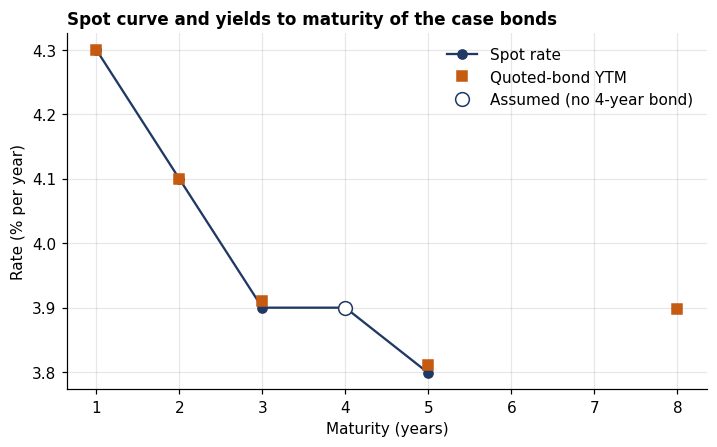

In [4]:
s1 = FACE / BONDS.loc["Alpha", "price"] - 1
s2 = (FACE / BONDS.loc["Beta", "price"]) ** 0.5 - 1
pv_gamma_coupons = 40 / (1 + s1) + 40 / (1 + s2) ** 2
s3 = (1040 / (BONDS.loc["Gamma", "price"] - pv_gamma_coupons)) ** (1 / 3) - 1

def s5_given(s4):
    pv = 35 / (1 + s1) + 35 / (1 + s2) ** 2 + 35 / (1 + s3) ** 3 + 35 / (1 + s4) ** 4
    return (1035 / (BONDS.loc["Delta", "price"] - pv)) ** (1 / 5) - 1

SPOT = pd.Series({1: s1, 2: s2, 3: s3, 4: s3, 5: s5_given(s3)})
sens = pd.DataFrame({"4-year spot": [s3 - 0.0025, s3, s3 + 0.0025], "Implied 5-year spot": [s5_given(s3 - 0.0025), s5_given(s3), s5_given(s3 + 0.0025)]},
                    index=["4Y spot -25 bp", "Base: 4Y = 3Y", "4Y spot +25 bp"])
display(pd.DataFrame({"Spot rate": SPOT.map(lambda v: f"{v:.4%}"),
                      "Source": ["Alpha, direct", "Beta, direct", "Gamma, bootstrapped", "Assumption: s4 = s3", "Delta, derived"]},
                     index=pd.Index(SPOT.index, name="Maturity (years)")))
display(sens.map(lambda v: f"{v:.4%}"))
print(f"Moving the 4-year assumption by 25 bp changes the implied 5-year spot by {abs(s5_given(s3 + 0.0025) - s5_given(s3)) * 1e4:.1f} bp: the assumption matters little for Delta.")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(SPOT.index, SPOT.values * 100, "-o", color="#1F3864", label="Spot rate")
ax.plot(BONDS.maturity, YTM.values * 100, "s", color="#C55A11", label="Quoted-bond YTM")
ax.plot([4], [SPOT[4] * 100], "o", mfc="white", mec="#1F3864", ms=9, label="Assumed (no 4-year bond)")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (% per year)"); ax.set_xticks([1, 2, 3, 4, 5, 6, 7, 8])
ax.set_title("Spot curve and yields to maturity of the case bonds", loc="left", fontweight="bold", fontsize=11)
ax.grid(alpha=0.3); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Duration and convexity

Macaulay duration is the present-value-weighted average time to cash flow; modified duration is Macaulay duration divided by (1 + y); convexity measures the curvature of the price-yield relation.
For a yield change Δ the approximations are ΔP/P ≈ −D<sub>mod</sub>·Δ (first order) and ΔP/P ≈ −D<sub>mod</sub>·Δ + ½·C·Δ² (second order).
Each approximation is compared with exact repricing for a ±100 basis point parallel shift.

In [5]:
def measures(name):
    y, p = YTM[name], BONDS.loc[name, "price"]
    cf = CF.loc[name]
    ts = np.arange(1, int(BONDS.loc[name, "maturity"]) + 1)
    flows = np.array([cf[2022 + t] for t in ts])
    pv = flows / (1 + y) ** ts
    mac = float((ts * pv).sum() / p)
    mod = mac / (1 + y)
    cvx = float((ts * (ts + 1) * flows / (1 + y) ** (ts + 2)).sum() / p)
    return mac, mod, cvx

DUR = pd.DataFrame({n: measures(n) for n in BONDS.index}, index=["Macaulay duration", "Modified duration", "Convexity"]).T
display(DUR.round(4))
assert np.isclose(DUR.loc["Alpha", "Macaulay duration"], 1) and np.isclose(DUR.loc["Beta", "Macaulay duration"], 2), "zero-coupon duration must equal maturity"

rows = []
for n in BONDS.index:
    for d in (0.01, -0.01):
        exact = price_at(n, YTM[n] + d) / BONDS.loc[n, "price"] - 1
        first = -DUR.loc[n, "Modified duration"] * d
        second = first + 0.5 * DUR.loc[n, "Convexity"] * d ** 2
        rows.append({"Bond": n, "Shift": f"{d * 1e4:+.0f} bp", "Exact": exact, "Duration only": first, "Duration + convexity": second,
                     "Error, duration only (bp of price)": (first - exact) * 1e4, "Error, with convexity (bp of price)": (second - exact) * 1e4})
APPROX = pd.DataFrame(rows)
view = APPROX.copy()
for c in ["Exact", "Duration only", "Duration + convexity"]:
    view[c] = view[c].map(lambda v: f"{v:.4%}")
for c in ["Error, duration only (bp of price)", "Error, with convexity (bp of price)"]:
    view[c] = view[c].map(lambda v: f"{v:+.1f}")
display(view.set_index(["Bond", "Shift"]))
print("Adding convexity reduces the approximation error for every bond and shift:",
      bool((APPROX["Error, with convexity (bp of price)"].abs() < APPROX["Error, duration only (bp of price)"].abs()).all()))

,Macaulay duration,Modified duration,Convexity
Alpha,1.0000,0.9588,1.8385
Beta,2.0000,1.9212,5.5367
Gamma,2.8862,2.7776,10.5528
Delta,4.6704,4.4989,25.4023
Epsilon,6.9182,6.6586,54.7855


Exact Duration only Duration + convexity Error, duration only (bp of price) Error, with convexity (bp of price)
Bond    Shift                                                                                                                      
Alpha   +100 bp  -0.9497%      -0.9588%             -0.9496%                               -0.9                                +0.0
        -100 bp   0.9681%       0.9588%              0.9680%                               -0.9                                -0.0
Beta    +100 bp  -1.8939%      -1.9212%             -1.8935%                               -2.7                                +0.0
        -100 bp   1.9493%       1.9212%              1.9489%                               -2.8                                -0.0
Gamma   +100 bp  -2.7257%      -2.7776%             -2.7249%                               -5.2                                +0.1
        -100 bp   2.8312%       2.7776%              2.8304%                               -5.4                                -0.1
Delta   +100 bp  -4.3747%      -4.4989%             -4.3719%                              -12.4                                +0.3
        -100 bp   4.6288%       4.4989%              4.6260%                              -13.0                                -0.3
Epsilon +100 bp  -6.3930%      -6.6586%             -6.3847%                              -26.6                                +0.8
        -100 bp   6.9413%       6.6586%              6.9325%                              -28.3                                -0.9

Adding convexity reduces the approximation error for every bond and shift: True


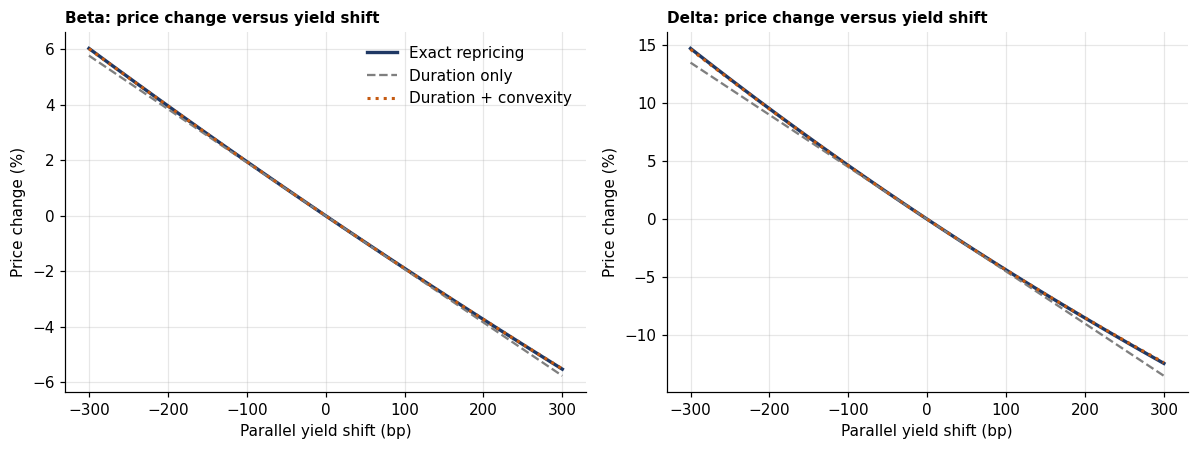

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
grid = np.linspace(-0.03, 0.03, 61)
for ax, n in zip(axes, ["Beta", "Delta"]):
    exact = np.array([price_at(n, YTM[n] + d) / BONDS.loc[n, "price"] - 1 for d in grid])
    first = -DUR.loc[n, "Modified duration"] * grid
    second = first + 0.5 * DUR.loc[n, "Convexity"] * grid ** 2
    ax.plot(grid * 1e4, exact * 100, color="#1F3864", lw=2.2, label="Exact repricing")
    ax.plot(grid * 1e4, first * 100, "--", color="#7F7F7F", label="Duration only")
    ax.plot(grid * 1e4, second * 100, ":", color="#C55A11", lw=2, label="Duration + convexity")
    ax.set_title(f"{n}: price change versus yield shift", loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel("Parallel yield shift (bp)"); ax.set_ylabel("Price change (%)")
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Liability funding: candidate strategies

**Candidate A (recommended): maturity-matched.** 2,400 Beta zero-coupon bonds pay USD 2.4m on 31 December 2024; 3,600 Delta bonds pay USD 3.6m principal on 31 December 2027 plus USD 126,000 of coupons each year.
**Candidate B (credible alternative): shorter-duration pre-funding.** The same Beta position, but the 2027 obligation is pre-funded with 3,215 Gamma bonds (maturing 2025) whose proceeds are held as cash at 0% until 2027.

In [7]:
UNITS = {"A": {"Beta": 2400, "Delta": 3600}, "B": {"Beta": 2400, "Gamma": 3215}}

def sleeve(cand):
    flows = pd.Series(0.0, index=YEARS)
    cost = 0.0
    for n, u in UNITS[cand].items():
        flows = flows.add(CF.loc[n] * u, fill_value=0.0)
        cost += BONDS.loc[n, "price"] * u
    return cost, flows

def ledger(cand):
    cost, flows = sleeve(cand)
    liab = pd.Series(0.0, index=YEARS); liab[2024] = LIAB_2024; liab[2027] = LIAB_2027
    f = flows.loc[2023:2027]
    out = pd.DataFrame({"Bond inflow": f, "Liability payment": liab.loc[2023:2027]})
    out["Net cash"] = out["Bond inflow"] - out["Liability payment"]
    out["Cumulative cash after payments (0% reinvestment)"] = out["Net cash"].cumsum()
    return cost, out

cost = {}; led = {}
for k in "AB":
    cost[k], led[k] = ledger(k)
summary = pd.DataFrame({
    "Initial funding cost": [cost["A"], cost["B"]],
    "Residual growth capital": [FUND - cost["A"], FUND - cost["B"]],
    "Cash after both payments, end-2027": [led["A"].iloc[-1, -1], led["B"].iloc[-1, -1]],
    "Minimum cash balance, 2023-2027": [led["A"].iloc[:, -1].min(), led["B"].iloc[:, -1].min()],
}, index=["Candidate A (Beta + Delta)", "Candidate B (Beta + Gamma + cash)"])
display(summary.map(usd))
print("Candidate A, annual funding ledger:"); display(led["A"].map(usd))
print("Candidate B, annual funding ledger:"); display(led["B"].map(usd))
assert abs(cost["A"] - 5_764_524.00) < 1e-6 and abs(FUND - cost["A"] - 6_235_476.00) < 1e-6
assert min(led["A"].iloc[:, -1].min(), led["B"].iloc[:, -1].min()) >= 0, "a liability is not covered"
print(f"Candidate B leaves {usd(cost['A'] - cost['B'])} more growth capital but ends 2027 with only {usd(led['B'].iloc[-1, -1])} of surplus cash, against {usd(led['A'].iloc[-1, -1])} for Candidate A.")

,Initial funding cost,Residual growth capital,"Cash after both payments, end-2027","Minimum cash balance, 2023-2027"
Candidate A (Beta + Delta),"$5,764,524.00","$6,235,476.00","$630,000.00","$126,000.00"
Candidate B (Beta + Gamma + cash),"$5,437,677.35","$6,562,322.65",$800.00,$800.00


Candidate A, annual funding ledger:


,Bond inflow,Liability payment,Net cash,Cumulative cash after payments (0% reinvestment)
2023,"$126,000.00",$0.00,"$126,000.00","$126,000.00"
2024,"$2,526,000.00","$2,400,000.00","$126,000.00","$252,000.00"
2025,"$126,000.00",$0.00,"$126,000.00","$378,000.00"
2026,"$126,000.00",$0.00,"$126,000.00","$504,000.00"
2027,"$3,726,000.00","$3,600,000.00","$126,000.00","$630,000.00"


Candidate B, annual funding ledger:


,Bond inflow,Liability payment,Net cash,Cumulative cash after payments (0% reinvestment)
2023,"$128,600.00",$0.00,"$128,600.00","$128,600.00"
2024,"$2,528,600.00","$2,400,000.00","$128,600.00","$257,200.00"
2025,"$3,343,600.00",$0.00,"$3,343,600.00","$3,600,800.00"
2026,$0.00,$0.00,$0.00,"$3,600,800.00"
2027,$0.00,"$3,600,000.00","$-3,600,000.00",$800.00


Candidate B leaves $326,846.65 more growth capital but ends 2027 with only $800.00 of surplus cash, against $630,000.00 for Candidate A.


**Funded status.** Both candidates cover the 2024 and 2027 payments under contractual cash flows. The comparison therefore turns on cost, reinvestment exposure and slack, not on whether the payment can be made.
Candidate B's 2027 cash rests on holding Gamma proceeds at 0% for two years and has almost no margin; Candidate A receives the 2027 principal on the payment date itself and keeps the coupon reserve.

2023        $-2,600.00
2024        $-2,600.00
2025    $-3,217,600.00
2026       $126,000.00
2027     $3,726,000.00
Extra initial cost of A over B: $326,846.65; extra end-2027 cash: $629,200.00
Internal rate of return of the incremental cash flows (A minus B): 3.68% per year
Interpretation: this is the annual 'price of certainty' of choosing A over B under 0% reinvestment of interim cash; it is a cost-of-certainty measure, not a forecast.
It is a contractual, default-free return, whereas the growth sleeve's required return (about 4.66% at 2.3% inflation) must be earned at risk, so the two are not directly comparable.
The choice of Candidate A rests on liability-date matching, slack and simplicity; the figure is reported so that the trade-off is explicit.


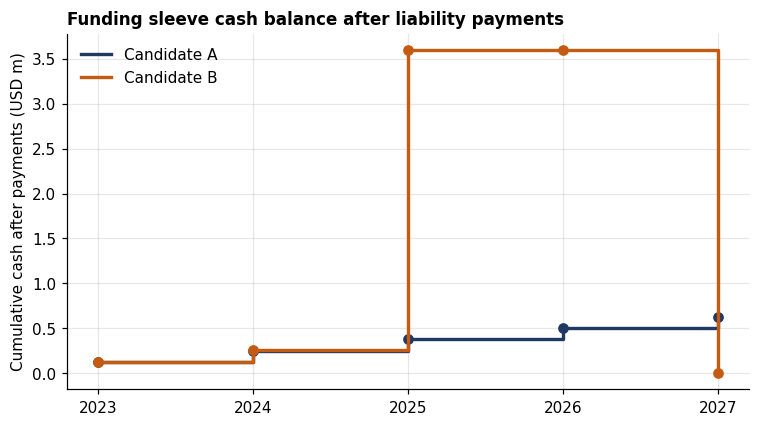

In [8]:
# Incremental analysis: what does the extra cost of Candidate A buy?
inc = (sleeve("A")[1] - sleeve("B")[1]).loc[2023:2027]
inc_cost = cost["A"] - cost["B"]
flows = [-inc_cost] + list(inc.values)
irr = brentq(lambda r: sum(cf / (1 + r) ** t for t, cf in enumerate(flows)), -0.5, 0.5)
print(pd.Series(inc.values, index=inc.index).map(usd).to_string())
print(f"Extra initial cost of A over B: {usd(inc_cost)}; extra end-2027 cash: {usd(led['A'].iloc[-1, -1] - led['B'].iloc[-1, -1])}")
print(f"Internal rate of return of the incremental cash flows (A minus B): {irr:.2%} per year")
print("Interpretation: this is the annual 'price of certainty' of choosing A over B under 0% reinvestment of interim cash; it is a cost-of-certainty measure, not a forecast.")
print("It is a contractual, default-free return, whereas the growth sleeve's required return (about 4.66% at 2.3% inflation) must be earned at risk, so the two are not directly comparable.")
print("The choice of Candidate A rests on liability-date matching, slack and simplicity; the figure is reported so that the trade-off is explicit.")

fig, ax = plt.subplots(figsize=(8, 4.2))
for k, col, lab in (("A", "#1F3864", "Candidate A"), ("B", "#C55A11", "Candidate B")):
    s = led[k].iloc[:, -1] / 1e6
    ax.step(s.index, s.values, where="post", color=col, lw=2.2, label=lab)
    ax.plot(s.index, s.values, "o", color=col)
ax.set_ylabel("Cumulative cash after payments (USD m)"); ax.set_xticks(YEARS[:5])
ax.set_title("Funding sleeve cash balance after liability payments", loc="left", fontsize=11, fontweight="bold")
ax.grid(alpha=0.3); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 7. Interest-rate scenarios: market value versus ability to pay

Scenario shifts are applied instantly at the decision date and are stress-test designs, not forecasts. For a bond held to maturity, the cash received on the liability dates does not depend on the shift;
only the interim market value changes. Exact repricing is used throughout.
Under the twist scenarios only the 2-year (Beta) and 5-year (Delta) yields are shifted, as in the workbook; the 3-year Gamma yield held by Candidate B is left unchanged, so Candidate B's twist results are indicative only.

In [9]:
def mv(cand, shifts):
    # shifts: dict bond -> yield shift; market value of the sleeve = units x price per 1,000 face
    return sum(u * price_at(n, YTM[n] + shifts.get(n, 0.0)) for n, u in UNITS[cand].items())

scen = {
    "Parallel +100 bp": {n: 0.01 for n in BONDS.index},
    "Parallel -100 bp": {n: -0.01 for n in BONDS.index},
    "Twist: 2Y +50 bp, 5Y -50 bp": {"Beta": 0.005, "Delta": -0.005},
    "Twist: 2Y -50 bp, 5Y -25 bp": {"Beta": -0.005, "Delta": -0.0025},
    "Twist: 2Y +50 bp, 5Y +25 bp": {"Beta": 0.005, "Delta": 0.0025},
}
rows = []
for name, sh in scen.items():
    row = {"Scenario": name}
    for k in "AB":
        base = mv(k, {})
        new = mv(k, sh)
        row[f"A: market value change" if k == "A" else "B: market value change"] = new - base
        row[f"A: % of initial cost" if k == "A" else "B: % of initial cost"] = (new - base) / base
    rows.append(row)
R = pd.DataFrame(rows).set_index("Scenario")
show = R.copy()
for c in show.columns:
    show[c] = show[c].map(lambda v: f"{v:.2%}" if "%" in c else f"{v:+,.0f}")
display(show)
print("Contractual cash at the liability dates under every scenario (hold to maturity):")
display(pd.DataFrame({"31 Dec 2024": [usd(2_400_000)], "31 Dec 2027": [usd(3_600_000)]}, index=["Beta and Delta principal (Candidate A)"]))
print("Funded status is unchanged by any scenario; the scenarios matter only if bonds must be sold before maturity.")

,A: market value change,A: % of initial cost,B: market value change,B: % of initial cost
Scenario,,,,
Parallel +100 bp,"-197,239",-3.42%,"-129,793",-2.39%
Parallel -100 bp,"+207,487",3.60%,"+134,421",2.47%
"Twist: 2Y +50 bp, 5Y -50 bp","+59,871",1.04%,"-21,122",-0.39%
"Twist: 2Y -50 bp, 5Y -25 bp","+61,639",1.07%,"+21,429",0.39%
"Twist: 2Y +50 bp, 5Y +25 bp","-60,768",-1.05%,"-21,122",-0.39%


Contractual cash at the liability dates under every scenario (hold to maturity):


,31 Dec 2024,31 Dec 2027
Beta and Delta principal (Candidate A),"$2,400,000.00","$3,600,000.00"


Funded status is unchanged by any scenario; the scenarios matter only if bonds must be sold before maturity.


## 8. The 2030 purchasing-power objective and the required growth return

The goal is USD 8.0m of December 2022 purchasing power at 31 December 2030, so the nominal target is 8.0m × (1 + π)<sup>8</sup>. The Delta coupons (USD 630,000 in total) are retained as terminal cash at 0%.
The required geometric return on the growth capital is ((target − coupon cash) / growth capital)<sup>1/8</sup> − 1. Two growth-capital conventions are reported:
the gross residual of USD 6,235,476 (bond workbook) and the amount actually invested in equities after the 10 basis point entry cost, USD 6,229,246.75 (Initial Decision Record).

,"Nominal target, 2030","Required CAGR, gross capital","Required CAGR, net capital (Decision Record)","If coupons ignored, net capital"
Inflation,,,,
2.0%,"$9,373,275.05",4.32%,4.33%,5.24%
2.3%,"$9,596,106.44",4.64%,4.66%,5.55%
3.0%,"$10,134,160.65",5.41%,5.42%,6.27%
4.0%,"$10,948,552.40",6.50%,6.51%,7.30%


Base case (2.3% inflation, FRED 10-year breakeven on 30 December 2022; a market reference, not an 8-year forecast): target $9,596,106.44.
The framework figure of 4.64% uses the gross capital; the Decision Record figure of 4.66% uses the capital after the entry cost. Both are correct under their stated conventions.


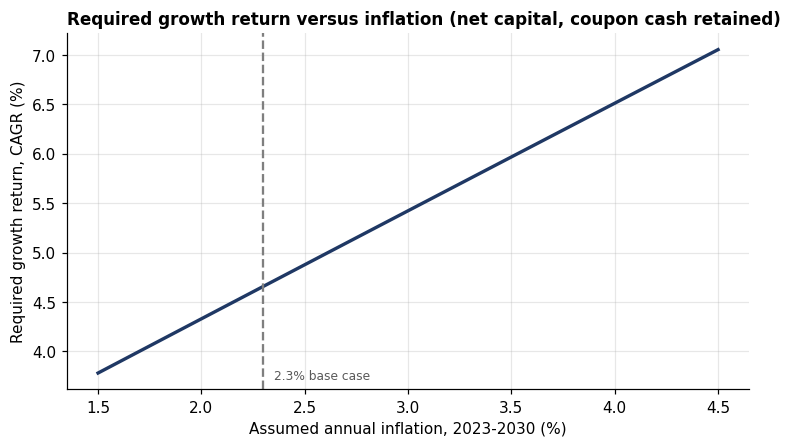

In [10]:
dw = pd.read_csv(ROOT / "portfolio_construction/evidence/decision_weights_confirmed.csv")
EQ_NET = round(float(dw.equity_purchase_USD.sum()), 2)
ENTRY_COST = float(Decimal(str(EQ_NET)) * Decimal("0.001"))
GROSS = FUND - cost["A"]
COUPON_CASH = 5 * 126_000
assert abs(EQ_NET + round(ENTRY_COST, 2) - GROSS) < 0.005, "gross and net growth capital do not reconcile"

rows = []
for pi in (0.02, 0.023, 0.03, 0.04):
    target = GOAL_REAL * (1 + pi) ** 8
    rows.append({"Inflation": f"{pi:.1%}", "Nominal target, 2030": usd(target),
                 "Required CAGR, gross capital": pct(((target - COUPON_CASH) / GROSS) ** (1 / 8) - 1),
                 "Required CAGR, net capital (Decision Record)": pct(((target - COUPON_CASH) / EQ_NET) ** (1 / 8) - 1),
                 "If coupons ignored, net capital": pct((target / EQ_NET) ** (1 / 8) - 1)})
display(pd.DataFrame(rows).set_index("Inflation"))
base_t = GOAL_REAL * 1.023 ** 8
print(f"Base case (2.3% inflation, FRED 10-year breakeven on 30 December 2022; a market reference, not an 8-year forecast): target {usd(base_t)}.")
print(f"The framework figure of 4.64% uses the gross capital; the Decision Record figure of 4.66% uses the capital after the entry cost. Both are correct under their stated conventions.")

pis = np.linspace(0.015, 0.045, 31)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(pis * 100, [(((GOAL_REAL * (1 + p) ** 8) - COUPON_CASH) / EQ_NET) ** (1 / 8) * 100 - 100 for p in pis], color="#1F3864", lw=2.2)
ax.axvline(2.3, color="#7F7F7F", ls="--"); ax.text(2.35, ax.get_ylim()[0] + 0.1, "2.3% base case", fontsize=8, color="#595959")
ax.set_xlabel("Assumed annual inflation, 2023-2030 (%)"); ax.set_ylabel("Required growth return, CAGR (%)")
ax.set_title("Required growth return versus inflation (net capital, coupon cash retained)", loc="left", fontsize=11, fontweight="bold")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 9. Reconciliation of the USD 12,000,000 initial fund

In [11]:
D = Decimal
q = lambda x: x.quantize(D("0.01"), rounding=ROUND_HALF_UP)
beta_cost = D(2400) * D("922.78"); delta_cost = D(3600) * D("986.07")
equities = D(str(EQ_NET)); fee = q(equities * D("0.001")); cash = D("0")
parts = {"2,400 Beta zero-coupon bonds": beta_cost, "3,600 Delta bonds": delta_cost, "Equities (net purchase)": equities,
         "One-time equity entry cost (10 bp)": fee, "Operating cash buffer": cash}
total = sum(parts.values())
display(pd.DataFrame({"USD": [f"{v:,.2f}" for v in parts.values()] + [f"{total:,.2f}"]}, index=list(parts) + ["Total"]))
assert total == D("12000000.00"), f"allocation does not reconcile: {total}"
print("Reconciliation: exact (difference USD 0.00).")

,USD
"2,400 Beta zero-coupon bonds","2,214,672.00"
"3,600 Delta bonds","3,549,852.00"
Equities (net purchase),"6,229,246.75"
One-time equity entry cost (10 bp),"6,229.25"
Operating cash buffer,0.00
Total,"12,000,000.00"


Reconciliation: exact (difference USD 0.00).


## 10. Cross-check against the Excel workbook

Every key output of the workbook is compared with the Python result above. The maximum absolute difference per item is reported; the notebook fails if any difference exceeds the tolerance.

In [12]:
import openpyxl
wb = openpyxl.load_workbook(WORKBOOK, data_only=True)
bf, rr = wb["BOND & FUNDING ANALYSIS"], wb["RATE RISK & DECISION"]
names = list(BONDS.index)
def col(ws, c, r0, n): return np.array([ws[f"{c}{r0 + i}"].value for i in range(n)], dtype=float)
checks = {
    "YTM": (col(bf, "G", 12, 5), YTM.values),
    "Spot rates 1Y-5Y": (col(bf, "B", 21, 5), SPOT.values),
    "Macaulay duration": (col(rr, "E", 12, 5), DUR["Macaulay duration"].values),
    "Modified duration": (col(rr, "F", 12, 5), DUR["Modified duration"].values),
    "Convexity": (col(rr, "G", 12, 5), DUR["Convexity"].values),
    "Candidate A cost, residual": (np.array([bf["E35"].value, bf["F35"].value], float), np.array([cost["A"], FUND - cost["A"]])),
    "Candidate B cost, residual": (np.array([bf["E43"].value, bf["F43"].value], float), np.array([cost["B"], FUND - cost["B"]])),
    "Cumulative coupon reserve 2023-2027": (col(bf, "H", 63, 5), np.cumsum([126_000.0] * 5)),
    "Parallel +100 bp, exact price (Beta, Delta)": (np.array([rr["G21"].value, rr["G22"].value], float),
                                                    np.array([price_at("Beta", YTM["Beta"] + .01), price_at("Delta", YTM["Delta"] + .01)])),
    "Curve scenario, exact price (Beta, Delta)": (np.array([rr["F27"].value, rr["F28"].value], float),
                                                  np.array([price_at("Beta", YTM["Beta"] + .005), price_at("Delta", YTM["Delta"] - .005)])),
}
rows = [{"Item": k, "Max absolute difference": float(np.max(np.abs(a - b)))} for k, (a, b) in checks.items()]
X = pd.DataFrame(rows).set_index("Item")
display(X.map(lambda v: f"{v:.2e}"))
assert (X["Max absolute difference"] < 1e-6).all(), "workbook and Python results disagree"
print("All workbook outputs reproduced independently.")
print()
print(f"Presentation note: workbook cell H40 reports Candidate B's 'cash at liability date' as {bf['H40'].value:,.0f} (principal only);")
print(f"including the three annual Gamma coupons of {40 * 3215:,.0f}, cash at the 2027 payment date is {led['B'].iloc[:, -1].loc[2026]:,.0f}.")

,Max absolute difference
Item,
YTM,7.51e-13
Spot rates 1Y-5Y,0.00e+00
Macaulay duration,8.34e-12
Modified duration,9.69e-12
Convexity,6.46e-11
"Candidate A cost, residual",0.00e+00
"Candidate B cost, residual",0.00e+00
Cumulative coupon reserve 2023-2027,1.46e-11
"Parallel +100 bp, exact price (Beta, Delta)",1.60e-09


All workbook outputs reproduced independently.

Presentation note: workbook cell H40 reports Candidate B's 'cash at liability date' as 3,215,000 (principal only);
including the three annual Gamma coupons of 128,600, cash at the 2027 payment date is 3,600,800.


## 11. Summary of findings (generated from the results above)

In [13]:
print(f"1. Funding: 2,400 Beta ({usd(2400 * 922.78)}) and 3,600 Delta ({usd(3600 * 986.07)}) cost {usd(cost['A'])} and leave {usd(FUND - cost['A'])} of residual capital; both obligations are covered by contractual principal on their due dates.")
print(f"2. Rate risk: modified durations are {DUR.loc['Beta', 'Modified duration']:.2f} (Beta) and {DUR.loc['Delta', 'Modified duration']:.2f} (Delta); a +100 bp parallel shift lowers the sleeve's market value by "
      f"{abs(R.loc['Parallel +100 bp', 'A: % of initial cost']):.2%} but leaves the cash received on the liability dates unchanged.")
print(f"3. Convexity: including convexity cuts the approximation error to at most {APPROX['Error, with convexity (bp of price)'].abs().max():.1f} bp of price for a 100 bp shift, "
      f"against up to {APPROX['Error, duration only (bp of price)'].abs().max():.1f} bp for duration alone.")
print(f"4. Alternative: Candidate B is {usd(cost['A'] - cost['B'])} cheaper but ends 2027 with {usd(led['B'].iloc[-1, -1])} of surplus cash (Candidate A: {usd(led['A'].iloc[-1, -1])}) and depends on 0% reinvestment of 2025 proceeds.")
print(f"5. Objective: at 2.3% inflation the nominal 2030 target is {usd(base_t)}; with the Delta coupon cash retained, the growth capital must compound at about "
      f"{(((base_t - COUPON_CASH) / EQ_NET) ** (1 / 8) - 1):.2%} per year (net capital) or {(((base_t - COUPON_CASH) / GROSS) ** (1 / 8) - 1):.2%} (gross capital). This is a feasibility benchmark, not a forecast.")

1. Funding: 2,400 Beta ($2,214,672.00) and 3,600 Delta ($3,549,852.00) cost $5,764,524.00 and leave $6,235,476.00 of residual capital; both obligations are covered by contractual principal on their due dates.
2. Rate risk: modified durations are 1.92 (Beta) and 4.50 (Delta); a +100 bp parallel shift lowers the sleeve's market value by 3.42% but leaves the cash received on the liability dates unchanged.
3. Convexity: including convexity cuts the approximation error to at most 0.9 bp of price for a 100 bp shift, against up to 28.3 bp for duration alone.
4. Alternative: Candidate B is $326,846.65 cheaper but ends 2027 with $800.00 of surplus cash (Candidate A: $630,000.00) and depends on 0% reinvestment of 2025 proceeds.
5. Objective: at 2.3% inflation the nominal 2030 target is $9,596,106.44; with the Delta coupon cash retained, the growth capital must compound at about 4.66% per year (net capital) or 4.64% (gross capital). This is a feasibility benchmark, not a forecast.


### Limitations

- The case bonds are fictional executable quotes: there are no historical returns, and post-2022 market values require modelled rates. All rate results are scenarios.
- The 4-year spot rate is an assumption; its effect on the implied 5-year spot is shown in Section 4.
- Interim cash is assumed to earn 0%. Positive reinvestment would raise Candidate B's margin more than Candidate A's, so the comparison is conservative for B.
- No defaults, taxes or transaction costs on the bonds, as stated in the case. The USD 250,000 liquidity-buffer stress in the workbook reduces residual growth capital to USD 5,985,476 and is not part of the base case.
- Approval status: the bond allocation is recommended and awaits group sign-off.